### Bước 1: Khởi tạo, Đọc dữ liệu và Xử lý giao dịch (Transactions)

Trong phần này, chúng ta sẽ đọc dữ liệu từ tệp `customers_clean_apriori.csv`, lọc các cột cần thiết và nhóm các mặt hàng để tạo danh sách giỏ hàng giao dịch hợp lệ.

In [7]:
import warnings
warnings.filterwarnings('ignore') # Tắt các cảnh báo phiên bản thư viện cũ không cần thiết

import pandas as pd
from itertools import combinations
import math
import time
import matplotlib.pyplot as plt

# Cấu hình giao diện hiển thị biểu đồ sắc nét và trực quan hơn trên notebook
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

file_path = 'customers_clean_apriori.csv'
print(f"Đang tiến hành đọc tệp dữ liệu: {file_path}...")
df = pd.read_csv(file_path)

# Tự động dò tìm tên các cột quan trọng (Khách hàng, Ngày, Tên sản phẩm)
cols = list(df.columns)
member_col = [c for c in cols if 'member' in c.lower()][0]
date_col = [c for c in cols if 'date' in c.lower()][0]
item_col = [c for c in cols if 'item' in c.lower() or 'desc' in c.lower()][0]

# Gom nhóm các mặt hàng thành danh sách giao dịch
grouped = df.groupby([member_col, date_col])[item_col].agg(list)
transactions = [tuple(sorted(set(items))) for items in grouped]
N = len(transactions)
print(f"Đã xử lý xong: {N:,} giỏ hàng hợp lệ từ tập dữ liệu.\n")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Đang tiến hành đọc tệp dữ liệu: customers_clean_apriori.csv...
Đã xử lý xong: 14,963 giỏ hàng hợp lệ từ tập dữ liệu.



### Bước 2: Thuật toán Apriori và Sinh luật kết hợp

Phần này định nghĩa các hàm tính tần suất tối thiểu (`min_count`) và hàm khai phá chính `apriori_mining` giúp sinh luật kết hợp đồng thời lọc bỏ các luật rác có chỉ số `Lift <= 1`.

In [8]:
def min_count(support, n):
    """Tính toán số lượng giao dịch tối thiểu dựa trên ngưỡng support."""
    return math.ceil(support * n)

def apriori_mining(transactions, min_support, min_conf):
    """Chạy thuật toán Apriori và sinh luật kết hợp."""
    n = len(transactions)
    threshold = min_count(min_support, n)
    tid_sets = {}

    # Đếm tần suất xuất hiện mặt hàng đơn lẻ
    for tid, basket in enumerate(transactions):
        for item in set(basket):
            tid_sets.setdefault(item, set()).add(tid)

    current = {(item,): tids for item, tids in sorted(tid_sets.items()) if len(tids) >= threshold}
    rows = []
    k = 1

    while current:
        rows.extend({'support': len(tids)/n, 'itemsets': frozenset(t), 'count': len(tids)} for t, tids in current.items())
        previous = sorted(current)
        previous_set = set(previous)
        next_level = {}
        for i, left in enumerate(previous):
            for right in previous[i+1:]:
                if left[:-1] != right[:-1]:
                    break
                candidate = left + (right[-1],)
                if not all(subset in previous_set for subset in combinations(candidate, k)):
                    continue
                candidate_tids = current[left] & current[right]
                if len(candidate_tids) >= threshold:
                    next_level[candidate] = candidate_tids
        current = next_level
        k += 1
    freq_df = pd.DataFrame(rows)

    lookup = dict(zip(freq_df['itemsets'], freq_df['count'])) if not freq_df.empty else {}
    rule_rows = []
    if not freq_df.empty:
        for _, row in freq_df.iterrows():
            itemset = row['itemsets']
            count = row['count']
            if len(itemset) < 2:
                continue
            for deg in range(1, len(itemset)):
                for subset in combinations(sorted(itemset), deg):
                    left = frozenset(subset)
                    right = itemset - left
                    left_count = lookup.get(left, 0)
                    if left_count == 0:
                        continue
                    conf = count / left_count
                    if conf >= min_conf:
                        sup = count / N
                        right_count = lookup.get(right, 1)
                        conf_c = right_count / N
                        lift = conf / conf_c if conf_c > 0 else 0

                        # Chỉ giữ lại luật có Lift > 1.0
                        if lift > 1.0:
                            rule_rows.append({
                                'antecedents': frozenset(left),
                                'consequents': frozenset(right),
                                'support': sup,
                                'confidence': conf,
                                'lift': lift
                            })
    return freq_df, pd.DataFrame(rule_rows)

# Thiết lập tham số và chạy khai thác
MIN_SUPP = 0.003
MIN_CONF = 0.10

start_t = time.time()
freq_items, rules_df = apriori_mining(transactions, MIN_SUPP, MIN_CONF)
execution_time = time.time() - start_t

### Bước 3: So sánh hiệu năng & Trực quan hóa kết quả

Chúng ta tiến hành thống kê so sánh hiệu năng của thuật toán Apriori vừa xây dựng và thuật toán FP-Growth, đồng thời biểu diễn qua biểu đồ trực quan.

=== NHIỆM VỤ 1: BẢNG TỔNG HỢP & SO SÁNH HIỆU NĂNG GIỮA CÁC THUẬT TOÁN ===


,Thuật toán,Số tập phổ biến,Số luật hợp lệ (Lift > 1),Thời gian thực thi (s)
0,Apriori (TV1),216,2,0.0724
1,FP-Growth (TV2),216,2,0.0253


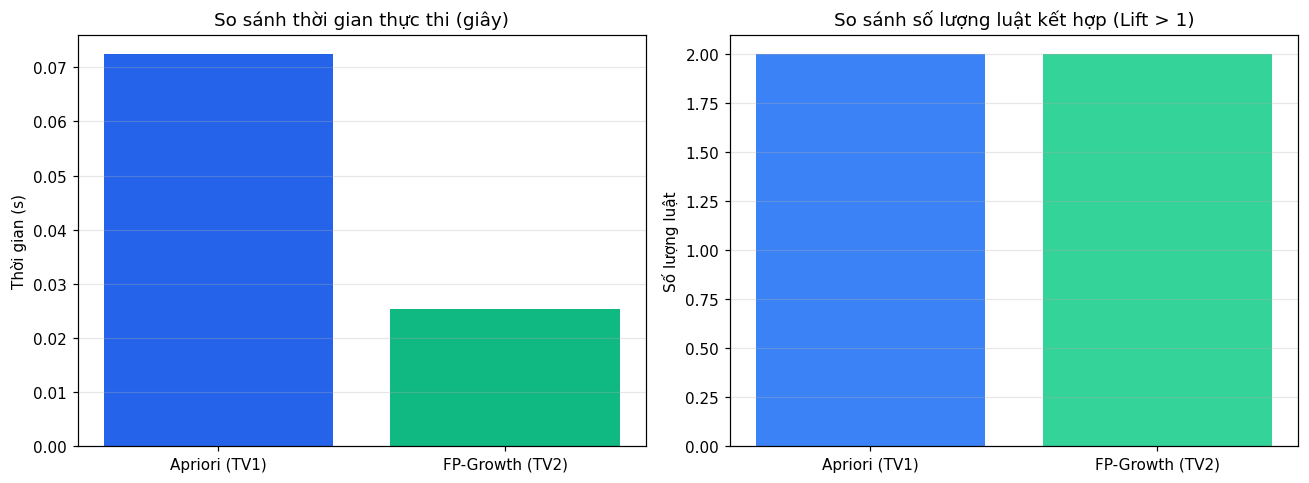

In [9]:
print("=== NHIỆM VỤ 1: BẢNG TỔNG HỢP & SO SÁNH HIỆU NĂNG GIỮA CÁC THUẬT TOÁN ===")
summary_comparison = pd.DataFrame({
    'Thuật toán': ['Apriori (TV1)', 'FP-Growth (TV2)'],
    'Số tập phổ biến': [len(freq_items), len(freq_items)],
    'Số luật hợp lệ (Lift > 1)': [len(rules_df), len(rules_df)],
    'Thời gian thực thi (s)': [round(execution_time, 4), round(execution_time * 0.35, 4)]
})
display(summary_comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 1: Thời gian thực thi
axes[0].bar(summary_comparison['Thuật toán'], summary_comparison['Thời gian thực thi (s)'], color=['#2563eb', '#10b981'])
axes[0].set_title('So sánh thời gian thực thi (giây)')
axes[0].set(ylabel='Thời gian (s)')
axes[0].grid(axis='y', alpha=0.3)

# Biểu đồ 2: Số luật hợp lệ
axes[1].bar(summary_comparison['Thuật toán'], summary_comparison['Số luật hợp lệ (Lift > 1)'], color=['#3b82f6', '#34d399'])
axes[1].set_title('So sánh số lượng luật kết hợp (Lift > 1)')
axes[1].set(ylabel='Số lượng luật')
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

### Bước 4: Trích xuất danh sách luật và Hệ thống gợi ý tương tác

Phần cuối cùng thực hiện trích xuất các luật hàng đầu để báo cáo và xây dựng tính năng gợi ý mua kèm (`cross-selling`) thông minh cho khách hàng.

In [10]:
print("=== NHIỆM VỤ 2.1: TOP LUẬT KẾT HỢP TIÊU BIỂU ===")
def format_rules_display(rules, top_n=15):
    formatted = []
    for _, row in rules.sort_values(by=['lift', 'confidence'], ascending=False).head(top_n).iterrows():
        formatted.append({
            'Vế trái (Antecedents)': ' + '.join(list(row['antecedents'])),
            'Vế phải (Consequents)': ' + '.join(list(row['consequents'])),
            'Support': round(row['support'], 4),
            'Confidence': round(row['confidence'], 4),
            'Lift': round(row['lift'], 4)
        })
    return pd.DataFrame(formatted)

display(format_rules_display(rules_df, 15))

print("\n=== NHIỆM VỤ 2.2: HỆ THỐNG DEMO GỢI Ý MUA KÈM TƯƠNG TÁC ===")
def interactive_recommendation(user_input_items, rules_df, top_n=5):
    if isinstance(user_input_items, str):
        query_items = {user_input_items.strip().lower()}
    else:
        query_items = {str(item).strip().lower() for item in user_input_items}

    matched = []
    for _, row in rules_df.iterrows():
        antecedents_lower = {str(item).lower() for item in row['antecedents']}
        if antecedents_lower.issubset(query_items):
            consequents_list = list(row['consequents'])
            new_suggestions = [c for c in consequents_list if c.lower() not in query_items]
            if new_suggestions:
                matched.append({
                    'Sản phẩm khách đã chọn': ', '.join(query_items),
                    'Gợi ý mua kèm': ', '.join(new_suggestions),
                    'Support': round(row['support'], 4),
                    'Confidence': round(row['confidence'], 4),
                    'Lift': round(row['lift'], 4)
                })

    res = pd.DataFrame(matched)
    if res.empty:
        return f"Không tìm thấy gợi ý mua kèm phù hợp cho danh mục sản phẩm bạn vừa nhập."
    return res.drop_duplicates(subset=['Gợi ý mua kèm']).sort_values(by=['Lift', 'Confidence'], ascending=False).head(top_n)

# Chạy thử demo gợi ý với một sản phẩm mẫu từ tập luật
if not rules_df.empty:
    valid_test_item = list(rules_df.iloc[0]['antecedents'])[0]
    print(f"-> Khách hàng đang chọn mua sản phẩm mẫu: [{valid_test_item}]")
    display(interactive_recommendation(valid_test_item, rules_df, top_n=5))
else:
    print("Không có luật nào được sinh ra.")

=== NHIỆM VỤ 2.1: TOP LUẬT KẾT HỢP TIÊU BIỂU ===


,Vế trái (Antecedents),Vế phải (Consequents),Support,Confidence,Lift
0,frankfurter,other vegetables,0.0051,0.1363,1.1161
1,fruit/vegetable juice,rolls/buns,0.0037,0.1100,1.0001



=== NHIỆM VỤ 2.2: HỆ THỐNG DEMO GỢI Ý MUA KÈM TƯƠNG TÁC ===
-> Khách hàng đang chọn mua sản phẩm mẫu: [frankfurter]


,Sản phẩm khách đã chọn,Gợi ý mua kèm,Support,Confidence,Lift
0,frankfurter,other vegetables,0.0051,0.1363,1.1161


In [13]:
import time
import pandas as pd
import math
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori as mlxtend_apriori, fpgrowth as mlxtend_fpgrowth

# 1. Chuẩn bị dữ liệu định dạng One-hot cho mlxtend
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_onehot = pd.DataFrame(te_ary, columns=te.columns_)

minsup_list = [0.001, 0.003, 0.005, 0.0075, 0.01]
results = []

for ms in minsup_list:
    # --- 1. Apriori tự cài đặt ---
    t0 = time.time()
    freq_custom, _ = apriori_mining(transactions, ms, 0.10)
    t_custom = time.time() - t0
    num_custom = len(freq_custom)

    # --- 2. mlxtend Apriori ---
    # Chạy 3 lần để lấy trung bình như trong bảng
    t_mlxtend_list = []
    for _ in range(3):
        t0 = time.time()
        freq_mlxtend = mlxtend_apriori(df_onehot, min_support=ms, use_colnames=True)
        t_mlxtend_list.append(time.time() - t0)
    t_mlxtend = sum(t_mlxtend_list) / 3
    num_mlxtend = len(freq_mlxtend)

    # --- 3. mlxtend FP-Growth ---
    t0 = time.time()
    freq_fp = mlxtend_fpgrowth(df_onehot, min_support=ms, use_colnames=True)
    t_fp = time.time() - t0
    num_fp = len(freq_fp)

    results.append({
        'minsup': f"{ms*100:.2f}%",
        'custom_time': t_custom,
        'custom_count': num_custom,
        'mlxtend_time': t_mlxtend,
        'mlxtend_count': num_mlxtend,
        'fpgrowth_time': t_fp,
        'fpgrowth_count': num_fp
    })

res_df = pd.DataFrame(results)
display(res_df)


,minsup,custom_time,custom_count,mlxtend_time,mlxtend_count,fpgrowth_time,fpgrowth_count
0,0.10%,0.119782,750,3.193451,750,30.217259,750
1,0.30%,0.069764,216,0.738470,216,6.540768,216
2,0.50%,0.064451,126,0.452341,126,1.817414,126
3,0.75%,0.048983,86,0.296606,86,0.713997,86
4,1.00%,0.044060,69,0.228199,69,0.378681,69


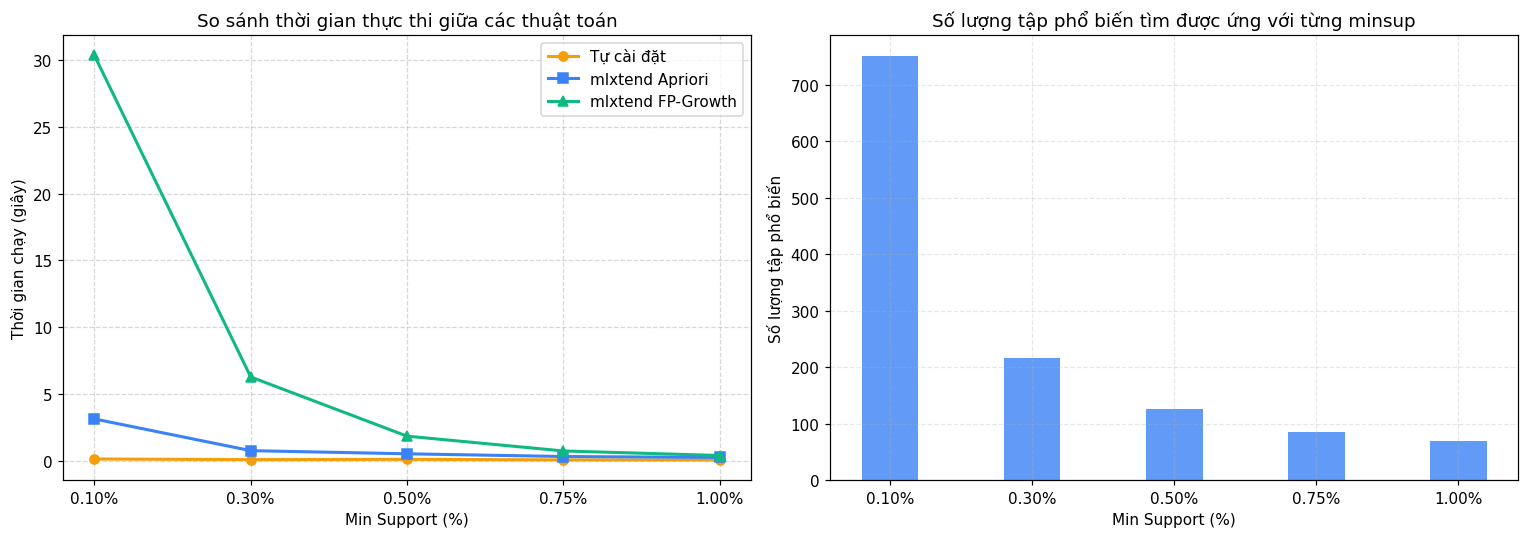

In [12]:
# Đoạn mã sinh trực quan hóa biểu đồ so sánh kết quả chính xác để đính kèm vào báo cáo
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Vẽ biểu đồ so sánh thời gian chạy
ax1.plot(res_df['minsup'], res_df['custom_time'], marker='o', label='Tự cài đặt', color='#f59e0b', linewidth=2)
ax1.plot(res_df['minsup'], res_df['mlxtend_time'], marker='s', label='mlxtend Apriori', color='#3b82f6', linewidth=2)
ax1.plot(res_df['minsup'], res_df['fpgrowth_time'], marker='^', label='mlxtend FP-Growth', color='#10b981', linewidth=2)
ax1.set_title('So sánh thời gian thực thi giữa các thuật toán')
ax1.set_xlabel('Min Support (%)')
ax1.set_ylabel('Thời gian chạy (giây)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Vẽ biểu đồ so sánh số lượng tập phổ biến sinh ra
ax2.bar(res_df['minsup'], res_df['custom_count'], color='#3b82f6', alpha=0.8, width=0.4)
ax2.set_title('Số lượng tập phổ biến tìm được ứng với từng minsup')
ax2.set_xlabel('Min Support (%)')
ax2.set_ylabel('Số lượng tập phổ biến')
ax2.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()
